
---Decision Tree (Entropy) Results---

Accuracy: 0.4131
Precision: 0.4201184502095047
Recall   : 0.41312453392990306
F1 Score : 0.4150558694537467

Classification Report:
              precision    recall  f1-score   support

         cel       0.44      0.40      0.42        95
         cla       0.35      0.36      0.36        96
         flu       0.28      0.31      0.29        85
         gac       0.50      0.42      0.45       151
         gel       0.42      0.36      0.39       139
         org       0.49      0.47      0.48       145
         pia       0.43      0.49      0.46       142
         sax       0.27      0.36      0.31       114
         tru       0.46      0.44      0.45       119
         vio       0.40      0.39      0.39       109
         voi       0.48      0.47      0.47       146

    accuracy                           0.41      1341
   macro avg       0.41      0.41      0.41      1341
weighted avg       0.42      0.41      0.42      1341


---Decision Tr

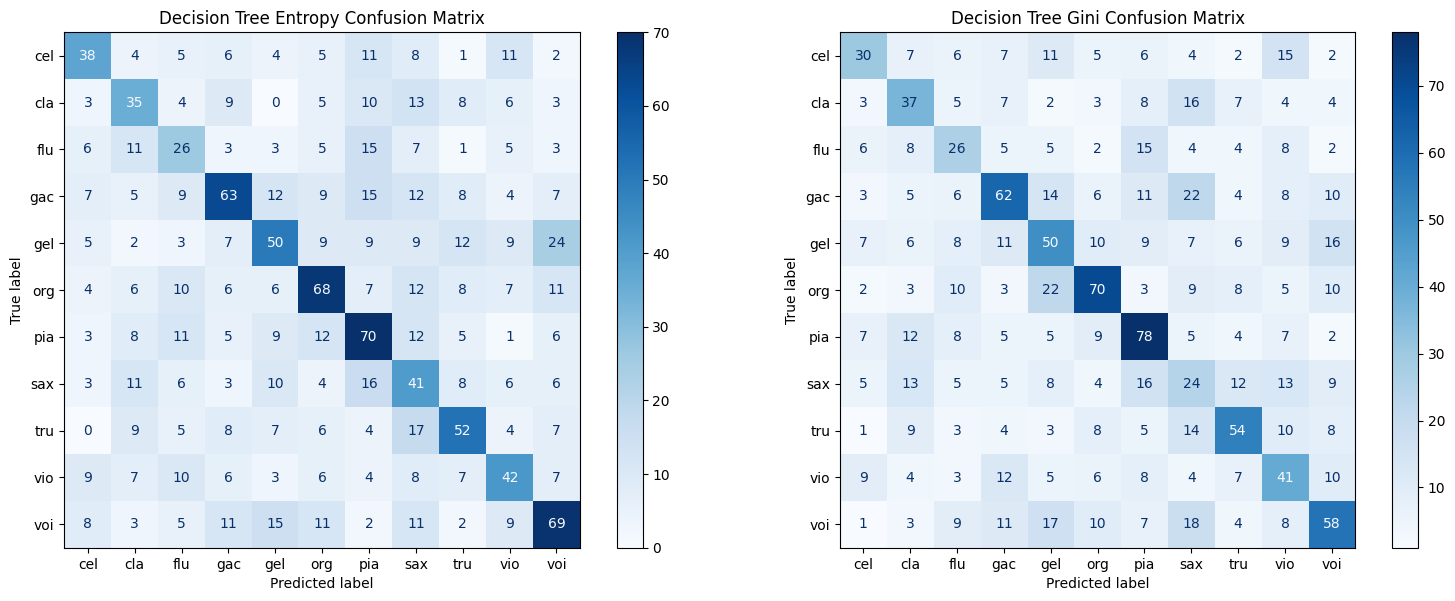


--- Decision Tree (Entropy/ID3) ---


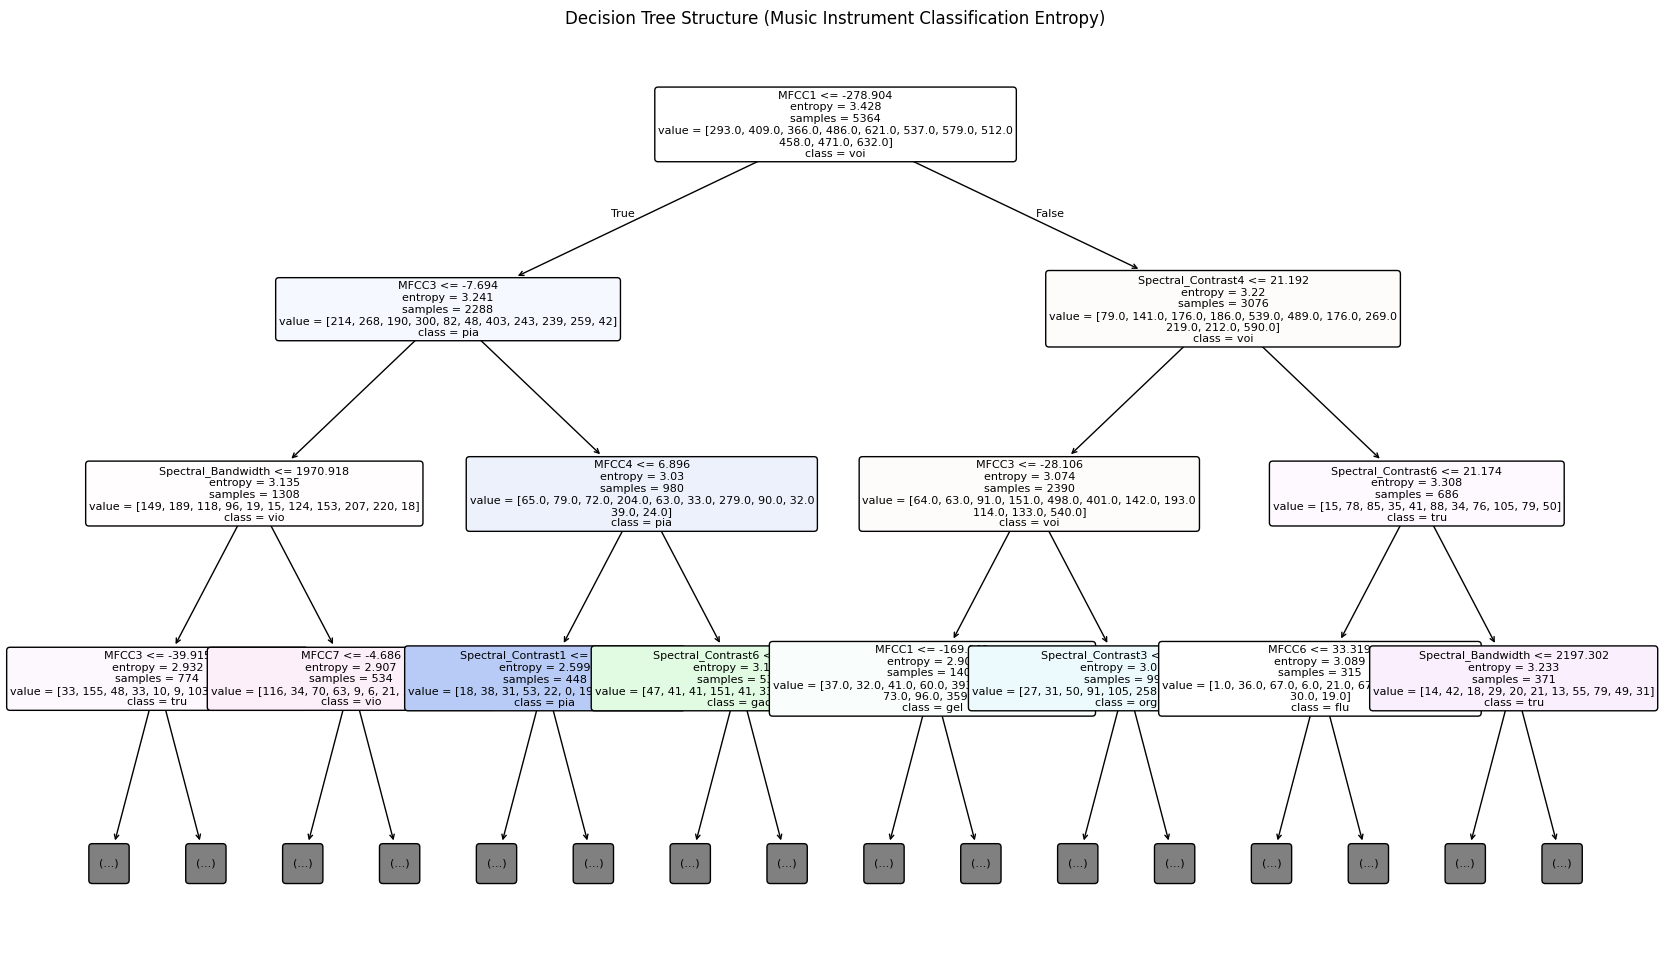


--- Decision Tree (Gini) ---


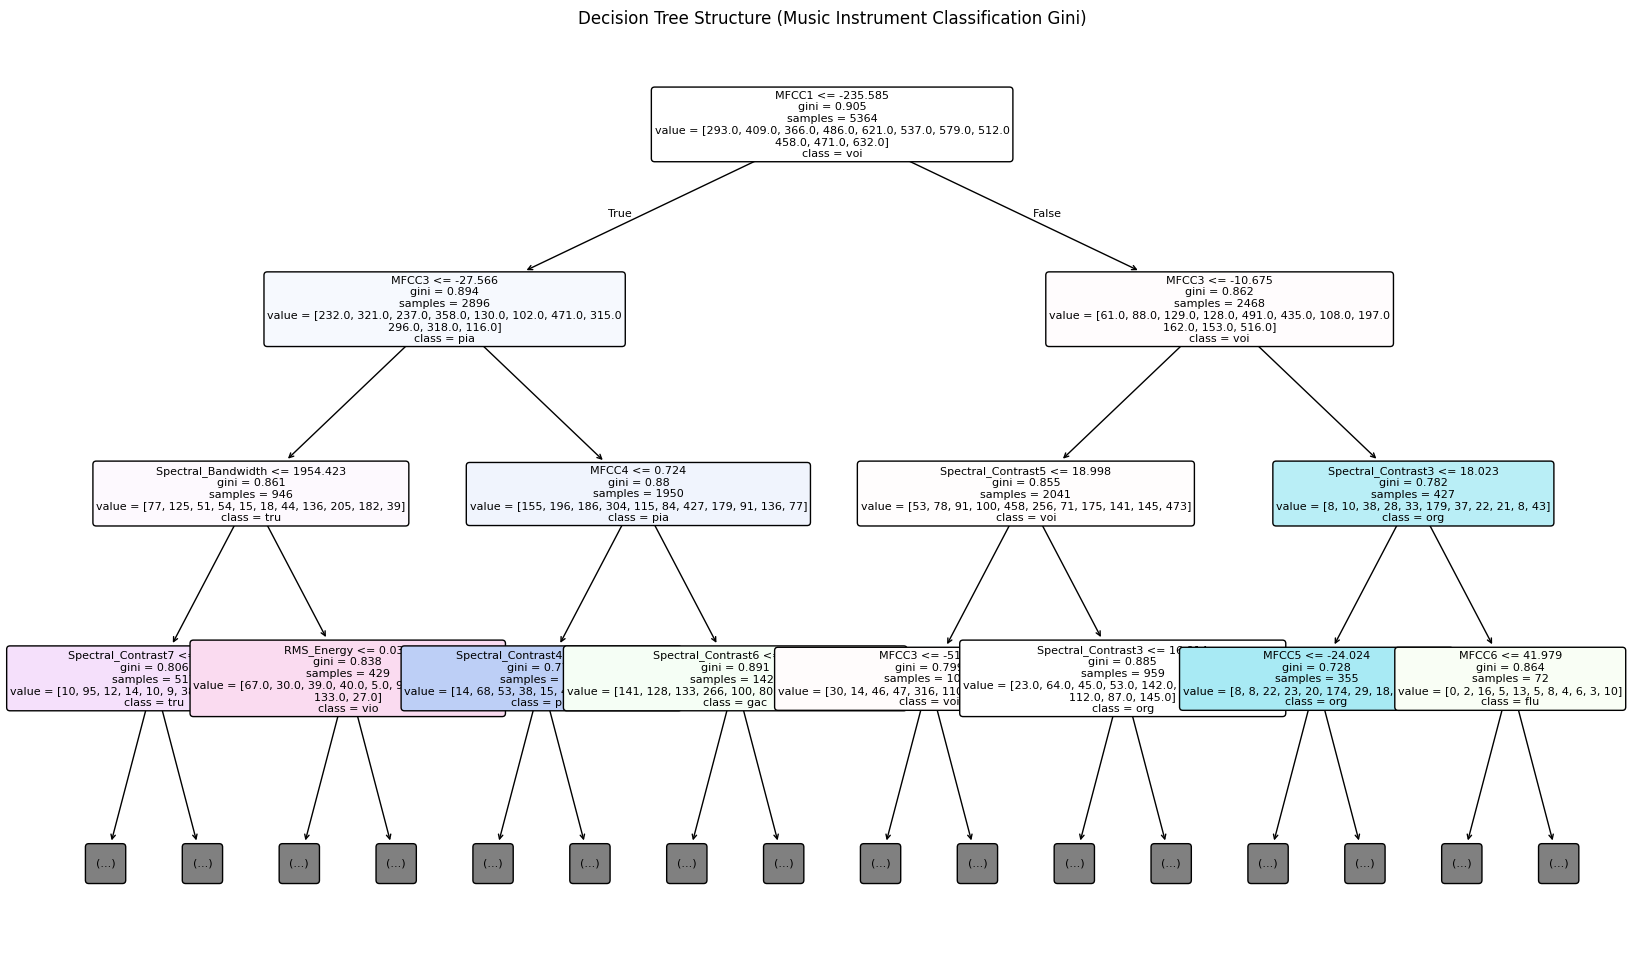

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# 1. Load the dataset
data=pd.read_csv(r"C:\Users\LENOVO\Documents\ML Project(Instrument Classifier)\Music Dataset.csv")
X = data.drop("Instrument",axis=1)
y = data["Instrument"]

# 2. Split into Training (80%) and Testing (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Decision Tree using Entropy (ID3 Style)
clf_entropy = DecisionTreeClassifier(criterion='entropy', max_depth=None)
clf_entropy.fit(X_train, y_train)
y_pred_entropy = clf_entropy.predict(X_test)

# 4. Decision Tree using Gini Index
clf_gini = DecisionTreeClassifier(criterion='gini', max_depth=None)
clf_gini.fit(X_train, y_train)
y_pred_gini = clf_gini.predict(X_test)

# 5. Compare Results
precision = precision_score(y_test, y_pred_entropy, average="weighted")
recall = recall_score(y_test, y_pred_entropy, average="weighted")
f1 = f1_score(y_test, y_pred_entropy, average="weighted")
print(f"\n---Decision Tree (Entropy) Results---\n")

print(f"Accuracy: {accuracy_score(y_test, y_pred_entropy):.4f}")
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_entropy))

print("\n---Decision Tree (Gini) Results---\n")
precision = precision_score(y_test, y_pred_gini, average="weighted")
recall = recall_score(y_test, y_pred_gini, average="weighted")
f1 = f1_score(y_test, y_pred_gini, average="weighted")
print(f"Accuracy: {accuracy_score(y_test, y_pred_gini):.4f}")
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_gini))

conf_mat_entropy = confusion_matrix(y_test, y_pred_entropy)
conf_mat_gini = confusion_matrix(y_test, y_pred_gini)

# 6. Display confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ConfusionMatrixDisplay(confusion_matrix=conf_mat_entropy, display_labels=clf_entropy.classes_).plot(ax=axes[0], cmap='Blues')
axes[0].set_title('Decision Tree Entropy Confusion Matrix')
ConfusionMatrixDisplay(confusion_matrix=conf_mat_gini, display_labels=clf_gini.classes_).plot(ax=axes[1], cmap='Blues')
axes[1].set_title('Decision Tree Gini Confusion Matrix')
plt.tight_layout()
plt.show()

# 7. View the Decision Rules for the Entropy Tree
print("\n--- Decision Tree (Entropy/ID3) ---")
plt.figure(figsize=(20, 12))
plot_tree(
    clf_entropy,
    feature_names=list(X.columns),
    class_names=clf_entropy.classes_,
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=3
)
plt.title("Decision Tree Structure (Music Instrument Classification Entropy)")
plt.savefig("music_tree_entropy.png")
plt.show()

# 8. View the Decision Rules for the Gini Tree
print("\n--- Decision Tree (Gini) ---")
plt.figure(figsize=(20, 12))
plot_tree(
    clf_gini,
    feature_names=list(X.columns),
    class_names=clf_gini.classes_,
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=3
)
plt.title("Decision Tree Structure (Music Instrument Classification Gini)")
plt.savefig("music_tree_gini.png")
plt.show()